In [ ]:
# flake8: noqa
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle
from matplotlib.gridspec import GridSpec
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy.special import ellipk
import sympy as sp
from IPython.display import display, HTML
from pathlib import Path

ASSETS = Path('practice_3_assets')
ASSETS.mkdir(exist_ok=True)
g = 9.81
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 160,
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10,
    'animation.embed_limit': 60,
})

def save_figure(fig, filename):
    dest = ASSETS / filename
    fig.savefig(dest, bbox_inches='tight')

def show_animation(fig, update, frames=56, interval=65, filename=None):
    """Анимация с элементами Play/Pause, перемоткой и отдельной HTML-копией."""
    anim = FuncAnimation(fig, update, frames=frames, interval=interval,
                         blit=False, repeat=True)
    html = anim.to_jshtml(fps=round(1000 / interval))
    if filename is not None:
        dest = ASSETS / filename
        dest.write_text('<!DOCTYPE html><html><head><meta charset="utf-8">'
                        '<title>Практическая 3 — анимация</title></head><body>'
                        + html + '</body></html>', encoding='utf-8')
    plt.close(fig)
    display(HTML(html))
    return anim


# 3.1. Задача о равномерном спуске

Условие. Найти кривую, по которой точка, находясь под действием тяжести и гладкой неподвижной опоры, движется с постоянной вертикальной скоростью.

### Аналитическое решение

Оси: $x$ — вправо, $y$ — вверх. Пусть $g>0$, $m>0$, $\dot y=-v$ с $v>0$ (постоянная скорость опускания), $x(0)=x_0$, $y(0)=y_0$, $\dot x(0)=u>0$. Тогда $\ddot y=0$, $y(t)=y_0-vt$.

По Ньютону: $m\ddot x=N_x$, $m\ddot y=-mg+N_y$, где $\vec N$ — нормальная реакция. Из $\ddot y=0$ следует $N_y=mg$. Для гладкой неподвижной опоры нормальная реакция перпендикулярна касательной скорости: $N_x\dot x+N_y\dot y=0$. Следовательно,

$$m\ddot x\dot x+mg(-v)=0,\qquad \boxed{\dot x\ddot x=gv}.$$

Интегрирование с начальным условием $\dot x(0)=u$ даёт:

$$\frac{d}{dt}(\dot x^2)=2gv,\qquad \boxed{\dot x(t)=\sqrt{u^2+2gvt}}.$$

Интегрируем ещё раз:

$$\boxed{x(t)=x_0+\frac{(u^2+2gvt)^{3/2}-u^3}{3gv}},\qquad \boxed{y(t)=y_0-vt}.$$

Исключая $t$, получаем явный вид кривой (для рассматриваемой ветви $x\ge x_0$):

$$\boxed{y(x)=y_0-\frac{\bigl(u^3+3gv(x-x_0)\bigr)^{2/3}-u^2}{2g}}.$$

Проверка. Вдоль движения $dy/dt=-v=\mathrm{const}$, при этом полная скорость и $\dot x$ увеличиваются. Здесь «равномерный» относится только к вертикальной составляющей скорости, а не к движению вдоль кривой.

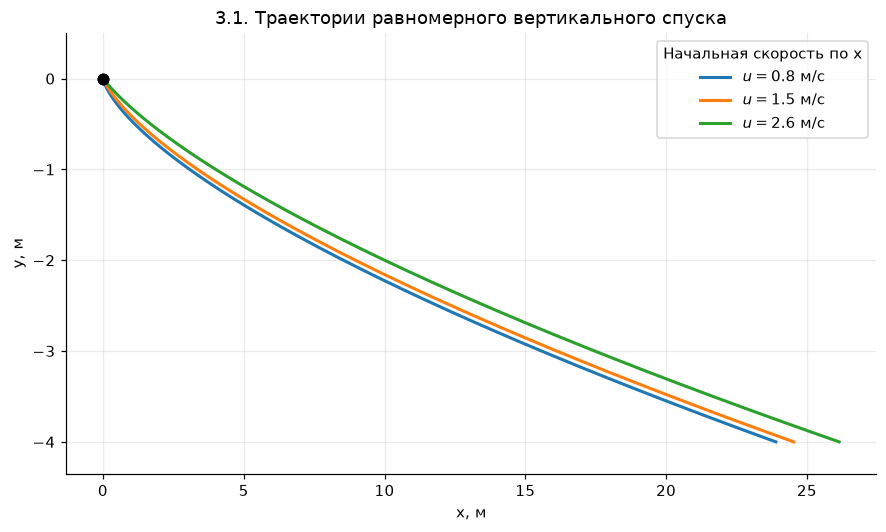

In [2]:
# 3.1 — статические графики для разных начальных горизонтальных скоростей
v31, x0_31, y0_31 = 1.0, 0.0, 0.0
t31 = np.linspace(0, 4.0, 400)
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for u in [0.8, 1.5, 2.6]:
    x = x0_31 + ((u*u + 2*g*v31*t31)**1.5 - u**3)/(3*g*v31)
    y = y0_31 - v31*t31
    ax.plot(x, y, lw=2, label=fr'$u={u:.1f}$ м/с')
    ax.scatter([x0_31], [y0_31], s=44, color='black', zorder=4)
ax.set(xlabel='x, м', ylabel='y, м', title='3.1. Траектории равномерного вертикального спуска')
ax.legend(title='Начальная скорость по x')
ax.set_ylim(-4.35, 0.5)
save_figure(fig, '3_1_descent.png')
plt.show()

In [3]:
# 3.1 — интерактивная анимация движения по кривой
u31, tmax31 = 1.5, 4.0
frame_t31 = np.linspace(0, tmax31, 56)
x_curve31 = ((u31*u31+2*g*v31*t31)**1.5-u31**3)/(3*g*v31)
y_curve31 = -v31*t31
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.plot(x_curve31, y_curve31, lw=2.5, label='Траектория')
ax.scatter([0], [0], marker='x', s=95, color='black', label='Старт')
(dot31,) = ax.plot([], [], 'o', ms=11, color='crimson', label='Шарик')
(trail31,) = ax.plot([], [], '-', lw=3, alpha=.35, color='crimson')
info31 = ax.text(.02, .06, '', transform=ax.transAxes, va='bottom',
                 bbox=dict(facecolor='white', edgecolor='lightgray', alpha=.9))
ax.set(xlim=(-1, max(x_curve31)+1), ylim=(-4.5, .65),
       xlabel='x, м', ylabel='y, м', title='3.1. Постоянная вертикальная скорость')
ax.legend(loc='upper right')
def update31(i):
    t=frame_t31[i]
    x=((u31*u31+2*g*v31*t)**1.5-u31**3)/(3*g*v31)
    y=-v31*t
    dot31.set_data([x],[y])
    mask=t31<=t
    trail31.set_data(x_curve31[mask], y_curve31[mask])
    info31.set_text(f't = {t:.2f} с   |   vy = {-v31:.2f} м/с\n'
                    f'vx = {np.sqrt(u31*u31+2*g*v31*t):.2f} м/с   |   y = {y:.2f} м')
    return dot31, trail31, info31
anim31 = show_animation(fig, update31, frames=len(frame_t31), interval=65,
                        filename='3_1_descent_animation.html')

# 3.2. Бильярд в прямоугольнике

Условие. Исследовать движение материальной точки со скоростью $\vec v=(v_x,v_y)$ внутри прямоугольника $0\le x\le a$, $0\le y\le b$ при идеальном упругом отражении от стенок.

### Аналитическое решение

Между столкновениями сила отсутствует: $\ddot x=\ddot y=0$. На вертикальной стенке $v_x\mapsto-v_x$, $v_y$ не меняется; на горизонтальной стенке $v_y\mapsto-v_y$, $v_x$ не меняется. Модуль скорости сохраняется.

Метод развёртки: вместо отражения шара зеркально отражаем прямоугольники и продолжаем движение по прямой:

$$X(t)=x_0+v_xt,\qquad Y(t)=y_0+v_yt.$$

Чтобы вернуть точку в исходный прямоугольник, применяем для каждой координаты отражающее «сворачивание»:

$$F_L(q)=L-\big|\,(q\bmod 2L)-L\,\big|,\qquad x(t)=F_a(X(t)),\quad y(t)=F_b(Y(t)).$$

Тор. Координаты $(X\bmod 2a,\,Y\bmod 2b)$ задают движение по плоскому тору (противоположные стороны прямоугольника $2a\times2b$ склеены). Для его 3D-изображения используются углы $\alpha=\pi X/a$ и $\beta=\pi Y/b$.

Периодичность: при ненулевых $v_x,v_y$ траектория периодична, если

$$\boxed{\frac{a\,v_y}{b\,v_x}\in\mathbb Q}.$$

При иррациональном отношении движение на торе непериодично, его орбита всюду плотна (в том числе можно говорить об эргодичности линейного потока). Конечный рисунок лишь иллюстрирует это свойство, а не доказывает его.

Гамильтонова формулировка между ударами: $H=(p_x^2+p_y^2)/(2m)$, $\dot x=p_x/m$, $\dot y=p_y/m$, $\dot p_x=\dot p_y=0$; при ударе нормальная компонента импульса меняет знак. Энергия $H$ сохраняется.

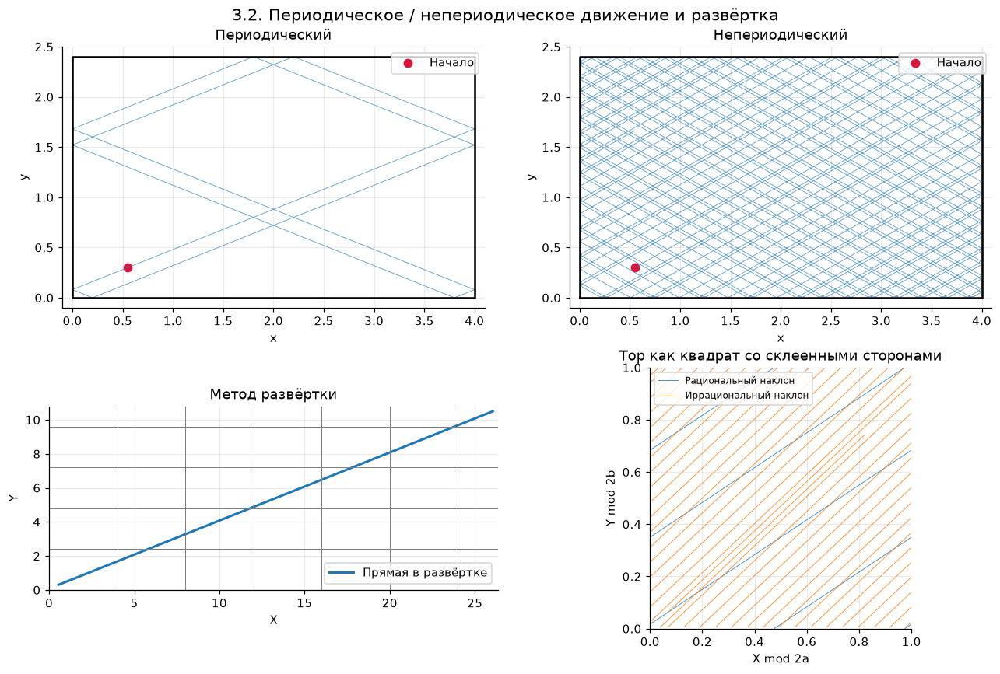

In [4]:
# 3.2 — модель отражений и статистические траектории
A32, B32, x032, y032 = 4.0, 2.4, 0.55, 0.30
VX32 = 1.5
VY32 = {'Периодический': 0.6, 'Непериодический': 0.6*np.sqrt(2)}

def fold32(q, L):
    return L - np.abs(np.mod(q, 2*L)-L)

def traj32(t, vy):
    X=x032+VX32*np.asarray(t)
    Y=y032+vy*np.asarray(t)
    return fold32(X,A32),fold32(Y,B32)

fig,axs=plt.subplots(2,2,figsize=(12,8))
for ax, (title, vy) in zip(axs.flat[:2], VY32.items()):
    t=np.linspace(0, 160 if title=='Непериодический' else 16.0, 6000)
    xs,ys=traj32(t,vy)
    ax.plot(xs,ys,lw=.55,alpha=.72)
    ax.plot([0,A32,A32,0,0],[0,0,B32,B32,0],color='black',lw=1.7)
    ax.scatter([x032],[y032],color='crimson',s=45,label='Начало')
    ax.set(xlim=(-.1,A32+.1),ylim=(-.1,B32+.1),xlabel='x',ylabel='y',title=title)
    ax.set_aspect('equal')
    ax.legend(loc='upper right')

# Развёртка на плоскость: прямая + сетка отражённых прямоугольников
ax=axs[1,0]
t=np.linspace(0,17,800)
X=x032+VX32*t
Y=y032+VY32['Периодический']*t
ax.plot(X,Y,color='tab:blue',lw=2,label='Прямая в развёртке')
for k in range(int(X.max()/A32)+2): ax.axvline(k*A32,color='gray',lw=.65)
for k in range(int(Y.max()/B32)+2): ax.axhline(k*B32,color='gray',lw=.65)
ax.set(xlim=(0,X.max()+.3),ylim=(0,Y.max()+.3),xlabel='X',ylabel='Y',title='Метод развёртки')
ax.set_aspect('equal')
ax.legend()

# Фундаментальный квадрат тора: сравнение незамкнутого и замкнутого потоков
ax=axs[1,1]
for title, vy, tmax in [('Рациональный наклон',.6,16.0),
                        ('Иррациональный наклон',.6*np.sqrt(2),100)]:
    tt=np.linspace(0,tmax,4500)
    uu=np.mod(x032+VX32*tt,2*A32)/(2*A32)
    vv=np.mod(y032+vy*tt,2*B32)/(2*B32)
    # не соединяем точки через противоположные стороны квадрата
    uu=np.where(np.abs(np.diff(uu,prepend=uu[0]))>.5,np.nan,uu)
    vv=np.where(np.abs(np.diff(vv,prepend=vv[0]))>.5,np.nan,vv)
    ax.plot(uu,vv,lw=.65,alpha=.8,label=title)
ax.set(xlim=(0,1),ylim=(0,1),xlabel='X mod 2a',ylabel='Y mod 2b',
       title='Тор как квадрат со склеенными сторонами')
ax.set_aspect('equal')
ax.legend(fontsize=8)
fig.suptitle('3.2. Периодическое / непериодическое движение и развёртка',fontsize=14)
fig.tight_layout()
save_figure(fig,'3_2_billiard.png')
plt.show()

In [5]:
# 3.2 — анимация двух режимов в прямоугольнике и на 3D-торе
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
fig=plt.figure(figsize=(10,7))
gs=GridSpec(2,2,figure=fig,width_ratios=[1.1,1])
case32=[('Периодический',.6),('Непериодический',.6*np.sqrt(2))]
axes_rect32=[]; axes_torus32=[]; balls32=[]; traces32=[]; points_t32=[]
U,V=np.meshgrid(np.linspace(0,2*np.pi,14),np.linspace(0,2*np.pi,9))
Rtor,rtor=1.25,.45
for row,(name,vy) in enumerate(case32):
    ax=fig.add_subplot(gs[row,0])
    ax.set(xlim=(0,A32),ylim=(0,B32),title=name+' — прямоугольник',xlabel='x',ylabel='y')
    ax.set_aspect('equal')
    ax.plot([0,A32,A32,0,0],[0,0,B32,B32,0],color='black',lw=1.4)
    (trace,)=ax.plot([],[],lw=1.4,alpha=.5)
    (ball,)=ax.plot([],[],'o',color='crimson',ms=8)
    axes_rect32.append(ax); traces32.append(trace); balls32.append(ball)
    tor=fig.add_subplot(gs[row,1],projection='3d')
    XX=(Rtor+rtor*np.cos(V))*np.cos(U)
    YY=(Rtor+rtor*np.cos(V))*np.sin(U)
    ZZ=rtor*np.sin(V)
    tor.plot_surface(XX,YY,ZZ,alpha=.17,linewidth=0,color='steelblue',shade=True)
    tor.set(xlim=(-1.85,1.85),ylim=(-1.85,1.85),zlim=(-1,1),title=name+' — тор')
    tor.set_axis_off()
    (point,)=tor.plot([],[],[],'o',color='crimson',ms=8)
    axes_torus32.append(tor); points_t32.append(point)
info32=fig.text(.5,.01,'',ha='center')
frame_t32=np.linspace(0,34,32)
def update32(i):
    t=frame_t32[i]
    for j,(_,vy) in enumerate(case32):
        path_t=np.linspace(0,t,200)
        tx,ty=traj32(path_t,vy)
        traces32[j].set_data(tx,ty)
        balls32[j].set_data([tx[-1]],[ty[-1]])
        U1=2*np.pi*np.mod(x032+VX32*t,2*A32)/(2*A32)
        V1=2*np.pi*np.mod(y032+vy*t,2*B32)/(2*B32)
        xp=(Rtor+rtor*np.cos(V1))*np.cos(U1)
        yp=(Rtor+rtor*np.cos(V1))*np.sin(U1)
        zp=rtor*np.sin(V1)
        points_t32[j].set_data([xp],[yp])
        points_t32[j].set_3d_properties([zp])
    info32.set_text(f't = {t:.2f} c   |   скорость между ударами постоянна; при ударе отражается нормальная компонента')
    return (*traces32,*balls32,*points_t32,info32)
fig.tight_layout(rect=[0,.035,1,1])
anim32=show_animation(fig,update32,frames=len(frame_t32),interval=100,
                      filename='3_2_billiard_animation.html')

# 3.3. Цепная линия

Условие. Найти форму равновесия однородной гибкой нерастяжимой нити плотности $\mu$ (кг/м), закреплённой в двух точках.

### Аналитическое решение

Пусть $H=T_x>0$ — постоянная горизонтальная составляющая натяжения, $s$ — длина дуги от нижней точки $x=x_c$ до текущей точки. Из баланса вертикальных сил: $T_y=\mu g s$. Для касательной к цепи $y'=T_y/H$. Учитывая $ds/dx=\sqrt{1+(y')^2}$, получаем

$$H y''=\mu g\sqrt{1+(y')^2}.$$

Вводим параметр натяжения $a=H/(\mu g)>0$:

$$\frac{dy'}{\sqrt{1+(y')^2}}=\frac{dx}{a}.$$

Разделяя переменные и интегрируя, получаем $\operatorname{arsinh}(y')=(x-x_c)/a$, то есть $y'=\sinh((x-x_c)/a)$. Интегрируем ещё раз:

$$\boxed{y(x)=y_{\min}+a\left[\cosh\left(\frac{x-x_c}{a}\right)-1\right]}.$$

В частности, с другим выбором нуля по вертикали $\boxed{y=a\cosh(x/a)}$, как в условии. При симметричных опорах $(0,0)$ и $(D,0)$:

$$\boxed{y(x)=a\left[\cosh\left(\frac{x-D/2}{a}\right)-\cosh\left(\frac{D}{2a}\right)\right]}.$$

Длина нити: $\boxed{L=2a\sinh(D/(2a))}$. Провисание: $h=a[\cosh(D/(2a))-1]$. Физический смысл: чем больше $a=H/(\mu g)$, тем сильнее горизонтальное натяжение и тем меньше провисание при фиксированном $D$.

Важно о нерастяжимости: при *неизменном* расстоянии $D$ разные значения $a$ дают разные длины нити $L$. Поэтому статический график сравнивает разные цепи. В анимации ниже одна нерастяжимая цепь имеет постоянную длину $L$, а меняется расстояние между опорами $D$; параметр $a$ пересчитывается из $L=2a\sinh(D/(2a))$.

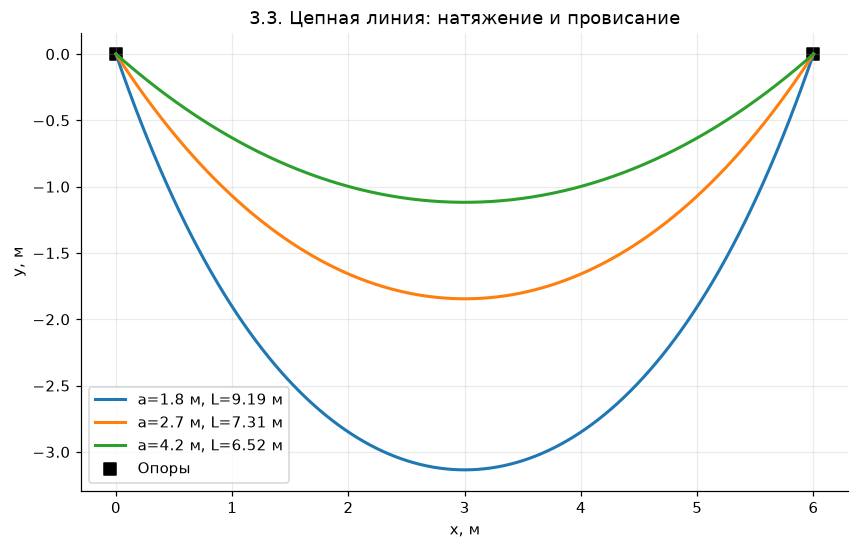

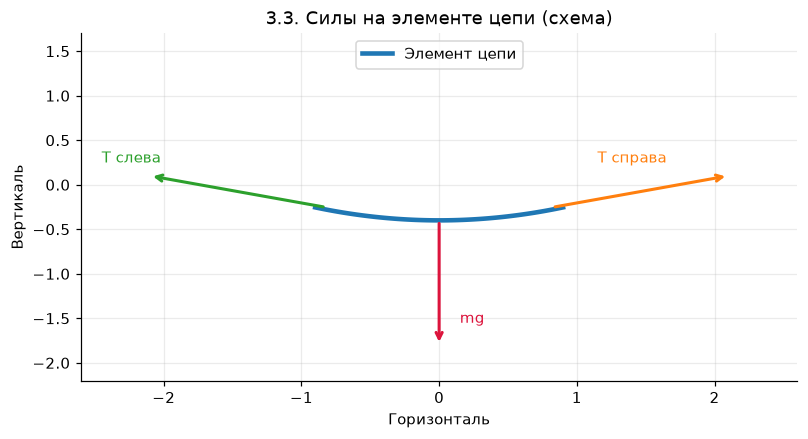

In [6]:
# 3.3 — семейство цепных линий при одинаковых опорах (разная длина нити)
D33,mu33=6.0,.5
xx=np.linspace(0,D33,550)
def ychain33(x,a,D):
    return a*(np.cosh((np.asarray(x)-D/2)/a)-np.cosh(D/(2*a)))

def length33(a,D):
    return 2*a*np.sinh(D/(2*a))

fig,ax=plt.subplots(figsize=(9,5.4))
for a in [1.8,2.7,4.2]:
    yy=ychain33(xx,a,D33)
    ax.plot(xx,yy,lw=2,label=f'a={a:.1f} м, L={length33(a,D33):.2f} м')
ax.scatter([0,D33],[0,0],marker='s',s=70,color='black',label='Опоры')
ax.set(xlabel='x, м',ylabel='y, м',title='3.3. Цепная линия: натяжение и провисание')
ax.legend()
save_figure(fig,'3_3_catenary.png')
plt.show()

# Физика сил: на фрагмент цепи действуют два натяжения и вес
fig,ax=plt.subplots(figsize=(8.4,4.1))
ax.set(xlim=(-2.6,2.6),ylim=(-2.2,1.7),title='3.3. Силы на элементе цепи (схема)',xlabel='Горизонталь',ylabel='Вертикаль')
segment_x=np.linspace(-.9,.9,90)
segment_y=.18*(segment_x**2)-.4
ax.plot(segment_x,segment_y,lw=3,color='tab:blue',label='Элемент цепи')
ax.annotate('',xy=(-2.1,.1),xytext=(-.82,segment_y[0]),arrowprops=dict(arrowstyle='->',color='tab:green',lw=2))
ax.annotate('',xy=(2.1,.1),xytext=(.82,segment_y[-1]),arrowprops=dict(arrowstyle='->',color='tab:orange',lw=2))
ax.annotate('',xy=(0,-1.8),xytext=(0,-.4),arrowprops=dict(arrowstyle='->',color='crimson',lw=2))
ax.text(-2.45,.25,'T слева',color='tab:green')
ax.text(1.15,.25,'T справа',color='tab:orange')
ax.text(.15,-1.55,'mg',color='crimson')
ax.legend(loc='upper center')
save_figure(fig,'3_3_catenary_forces.png')
plt.show()

In [7]:
# 3.3 — анимация: НЕРАСТЯЖИМАЯ цепь постоянной длины, опоры сближаются и расходятся
Lfixed33=7.5
Dframes33=5.15 + 1.0*np.sin(np.linspace(0,2*np.pi,64))

def find_a33(D, L):
    if D>=L: raise ValueError('Нужна длина цепи L > расстояния между опорами D')
    return brentq(lambda a: length33(a,D)-L, 0.15, 1000)

Aframes33=np.array([find_a33(D,Lfixed33) for D in Dframes33])
fig,ax=plt.subplots(figsize=(9.2,5.4))
ax.set(xlim=(-.3,6.6),ylim=(-4.3,.9),xlabel='x, м',ylabel='y, м',
       title='3.3. Нерастяжимая цепь: изменение расстояния между опорами')
(chain_line33,)=ax.plot([],[],lw=3,color='tab:blue')
(supports33,)=ax.plot([],[],'ks',ms=8)
info33=ax.text(.02,.07,'',transform=ax.transAxes,va='bottom',
               bbox=dict(facecolor='white',edgecolor='lightgray',alpha=.9))
force_arrows33=[]

def update33(i):
    D=Dframes33[i]; a=Aframes33[i]
    x=np.linspace(0,D,450)
    y=ychain33(x,a,D)
    chain_line33.set_data(x,y)
    supports33.set_data([0,D],[0,0])
    sag=a*(np.cosh(D/(2*a))-1)
    H=mu33*g*a
    info33.set_text(f'Расстояние D = {D:.2f} м   |   длина L = {Lfixed33:.2f} м (постоянна)\n'
                    f'a = {a:.2f} м   |   провисание h = {sag:.2f} м   |   H = {H:.1f} Н')
    for artist in force_arrows33: artist.remove()
    force_arrows33.clear()
    # Натяжение на небольшой участок ближе к правой опоре + сила тяжести вниз
    xpoint=.70*D; ypoint=float(ychain33(xpoint,a,D))
    slope=np.sinh((xpoint-D/2)/a)
    theta=np.arctan(slope)
    scale=.72
    force_arrows33.append(ax.arrow(xpoint,ypoint,scale*np.cos(theta),scale*np.sin(theta),
                    width=.018,color='tab:orange',length_includes_head=True,zorder=5))
    force_arrows33.append(ax.arrow(xpoint,ypoint,0,-.75,
                    width=.018,color='crimson',length_includes_head=True,zorder=5))
    return chain_line33,supports33,info33,*force_arrows33

anim33=show_animation(fig,update33,frames=len(Dframes33),interval=70,
                      filename='3_3_catenary_animation.html')

# 3.4. Задача о таутохроне (изохронная кривая)

Условие. Найти форму гладкой кривой, по которой точка, отпущенная без начальной скорости с любой высоты, достигает нижней точки за одно и то же время. В классической постановке такой кривой служит перевёрнутая циклоида.

### Аналитическое решение через уравнение Абеля

Пусть $h$ — высота над низшей точкой, а $q(h)$ — длина дуги от неё до точки на одной ветви. Из сохранения энергии при старте с высоты $h_0$:

$$\frac12 m\dot q^2 + mgh = mgh_0 \quad\Rightarrow\quad |\dot q|=\sqrt{2g(h_0-h)}.$$

Время спуска:

$$T(h_0)=\frac{1}{\sqrt{2g}}\int_0^{h_0}\frac{q'(h)}{\sqrt{h_0-h}}\,dh.$$

Требование $T(h_0)=T_0=\text{const}$ даёт интегральное уравнение Абеля. По формуле обращения Абеля:

$$q'(h)=\frac{T_0\sqrt{2g}}{\pi\sqrt{h}},\qquad
\boxed{q(h)=\frac{2T_0\sqrt{2g}}{\pi}\sqrt{h}}.$$

Отсюда $h\propto q^2$. Введём параметр $R>0$ и положим $h=q^2/(8R)$. Тогда из потенциальной энергии следует уравнение движения вдоль кривой:

$$\ddot q=-g\frac{dh}{dq}=-\frac{g}{4R}q.$$

Это гармонический осциллятор с $\omega=\sqrt{g/(4R)}$, поэтому $q(t)=q_0\cos(\omega t)$ при старте из покоя. Отпускаем шарик при $q=q_0$: до нижней точки $q=0$ он дойдёт за четверть периода:

$$\boxed{T_0=\frac{\pi}{2\omega}=\pi\sqrt{\frac{R}{g}}},$$

и это время не зависит от $q_0$, то есть от начальной высоты.

### Параметрическое уравнение перевёрнутой циклоиды

$$\boxed{x(\theta)=R(\theta-\sin\theta),\quad y(\theta)=R(\cos\theta-1),\quad 0\le\theta\le2\pi}.$$

Верхние точки — острия при $\theta=0,2\pi$, нижняя точка — при $\theta=\pi$. Длина дуги, отсчитанная от нижней точки со знаком:

$$q(\theta)=-4R\cos(\theta/2),\qquad h(\theta)=R(1+\cos\theta)=\frac{q(\theta)^2}{8R}.$$

Так полученная из интегрального уравнения зависимость $h\propto q^2$ действительно реализуется перевёрнутой циклоидой. Следовательно, циклоида — искомая таутохронная кривая.

Геометрическое построение: циклоида — траектория точки окружности радиуса $R$, катящейся без проскальзывания вдоль прямой; здесь окружность расположена ниже горизонтали, а полученную кривую используем как желоб.

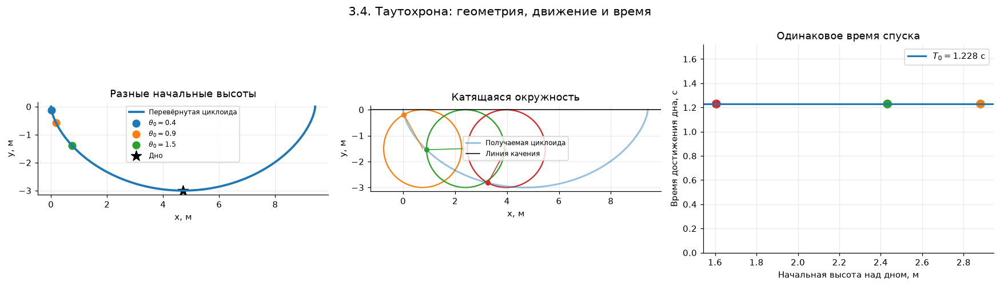

Время скатывания для всех стартовых точек: 1.22846 с


In [8]:
# 3.4 — статическая кривая, геометрическое построение и равенство времён
R34=1.5
omega34=np.sqrt(g/(4*R34))
Tbottom34=np.pi*np.sqrt(R34/g)
theta34=np.linspace(0,2*np.pi,900)

def cycloid34(theta):
    theta=np.asarray(theta)
    return R34*(theta-np.sin(theta)), R34*(np.cos(theta)-1)

xcy,ycy=cycloid34(theta34)
starts34=[.4,.9,1.5]
fig,axs=plt.subplots(1,3,figsize=(16,4.6))
ax=axs[0]
ax.plot(xcy,ycy,lw=2.5,color='tab:blue',label='Перевёрнутая циклоида')
for theta0 in starts34:
    x,y=cycloid34(theta0)
    ax.scatter([x],[y],s=68,label=fr'$\theta_0={theta0:.1f}$')
ax.scatter([np.pi*R34],[-2*R34],marker='*',s=150,color='black',label='Дно')
ax.set(xlabel='x, м',ylabel='y, м',title='Разные начальные высоты')
ax.set_aspect('equal'); ax.legend(fontsize=8)

ax=axs[1]
ax.plot(xcy,ycy,alpha=.45,lw=2,label='Получаемая циклоида')
for tg,col in [(0.5,'tab:orange'),(1.6,'tab:green'),(2.65,'tab:red')]:
    centre=(R34*tg,-R34)
    ax.add_patch(Circle(centre,R34,fill=False,lw=1.5,color=col))
    xp,yp=cycloid34(tg)
    ax.plot([centre[0],xp],[centre[1],yp],color=col,lw=1)
    ax.plot([xp],[yp],'o',color=col,ms=5)
ax.axhline(0,color='black',lw=1,label='Линия качения')
ax.set(xlabel='x, м',ylabel='y, м',title='Катящаяся окружность')
ax.set_aspect('equal'); ax.legend(fontsize=8)

ax=axs[2]
heights34=[float(R34*(1+np.cos(t))) for t in starts34]
ax.scatter(heights34,[Tbottom34]*len(starts34),s=85,c=['tab:orange','tab:green','tab:red'])
ax.axhline(Tbottom34,color='tab:blue',lw=2,label=fr'$T_0={Tbottom34:.3f}$ с')
ax.set(xlabel='Начальная высота над дном, м',ylabel='Время достижения дна, с',
       title='Одинаковое время спуска',ylim=(0,1.4*Tbottom34))
ax.legend()
fig.suptitle('3.4. Таутохрона: геометрия, движение и время',fontsize=14)
fig.tight_layout()
save_figure(fig,'3_4_tautochrone.png')
plt.show()
print(f'Время скатывания для всех стартовых точек: {Tbottom34:.5f} с')

In [9]:
# 3.4 — анимация: шарики стартуют с разных высот и одновременно достигают дна
fig,axs=plt.subplots(1,2,figsize=(13,5.2))
ax=axs[0]
ax.plot(xcy,ycy,lw=2.4,color='tab:blue')
ax.plot([np.pi*R34],[-2*R34],'k*',ms=10,label='Нижняя точка')
colors34=['tab:orange','tab:green','tab:red']
balls34=[];trails34=[]
for color,theta0 in zip(colors34,starts34):
    (ball,)=ax.plot([],[],'o',ms=9,color=color,label=fr'$\theta_0={theta0:.1f}$')
    (trail,)=ax.plot([],[],lw=2,alpha=.45,color=color)
    balls34.append(ball); trails34.append(trail)
ax.set(xlim=(-.3,2*np.pi*R34+.3),ylim=(-2.5*R34,.5*R34),
       xlabel='x, м',ylabel='y, м',title='Одновременное скатывание')
ax.set_aspect('equal')
ax.legend(fontsize=8,loc='upper center')

axroll=axs[1]
axroll.plot(xcy,ycy,color='gray',lw=1,alpha=.6)
axroll.axhline(0,color='black',lw=1)
(circle34,)=axroll.plot([],[],lw=1.8,color='tab:purple')
(radius34,)=axroll.plot([],[],lw=1.5,color='tab:purple')
(point34,)=axroll.plot([],[],'o',color='crimson',ms=7)
(traced34,)=axroll.plot([],[],color='tab:purple',lw=2)
axroll.set(xlim=(-.3,2*np.pi*R34+.3),ylim=(-2.5*R34,.5*R34),
           xlabel='x, м',ylabel='y, м',title='Построение циклоиды окружностью')
axroll.set_aspect('equal')
info34=fig.text(.5,.02,'',ha='center')
frame_t34=np.linspace(0,Tbottom34,40)
phis34=np.linspace(0,2*np.pi,150)
def update34(i):
    t=frame_t34[i]
    for j,theta0 in enumerate(starts34):
        q0=-4*R34*np.cos(theta0/2)
        q=q0*np.cos(omega34*t)
        theta=2*np.arccos(np.clip(-q/(4*R34),-1,1))
        xb,yb=cycloid34(theta)
        balls34[j].set_data([xb],[yb])
        t_hist=np.linspace(0,t,110)
        q_hist=q0*np.cos(omega34*t_hist)
        th_hist=2*np.arccos(np.clip(-q_hist/(4*R34),-1,1))
        traces_x,traces_y=cycloid34(th_hist)
        trails34[j].set_data(traces_x,traces_y)
    # Условное качение окружности для иллюстрации геометрии
    theta_roll=2*np.pi*(t/Tbottom34)
    cx,cy=R34*theta_roll,-R34
    circle34.set_data(cx+R34*np.cos(phis34),cy+R34*np.sin(phis34))
    px,py=cycloid34(theta_roll)
    radius34.set_data([cx,px],[cy,py])
    point34.set_data([px],[py])
    trace_theta=np.linspace(0,theta_roll,220)
    xx,yy=cycloid34(trace_theta)
    traced34.set_data(xx,yy)
    info34.set_text(f't = {t:.3f} с   |   одинаковое время до дна: T = {Tbottom34:.3f} с')
    return (*balls34,*trails34,circle34,radius34,point34,traced34,info34)
fig.tight_layout(rect=[0,.05,1,1])
anim34=show_animation(fig,update34,frames=len(frame_t34),interval=68,
                      filename='3_4_tautochrone_animation.html')

# 3.5. Движение математического маятника

Условие. Исследовать движение идеального маятника с точечной массой $m$ на невесомом жёстком стержне длины $\ell$ в поле тяжести. Сравнить линейные и нелинейные режимы, построить фазовый портрет и зависимость периода от амплитуды.

### Аналитическое решение

Угол отклонения от нижней вертикали обозначим $\theta$, положительное направление — против часовой стрелки. Касательная сила тяжести равна $-mg\sin\theta$. Из второго закона Ньютона вдоль касательной:

$$m\ell\ddot\theta=-mg\sin\theta\quad\Rightarrow\quad\boxed{\ddot\theta+\frac{g}{\ell}\sin\theta=0}.$$

Малые углы. При $|\theta|\ll1$ радиан $\sin\theta\simeq\theta$:

$$\ddot\theta+\omega_0^2\theta=0,\qquad \omega_0=\sqrt{g/\ell},$$

$$\boxed{\theta_{\mathrm{lin}}(t)=\theta_0\cos(\omega_0t)+\frac{\dot\theta_0}{\omega_0}\sin(\omega_0t)},\qquad \boxed{T_{\mathrm{lin}}=2\pi\sqrt{\ell/g}}.$$

Нелинейный случай. Система записывается как $\dot\theta=\omega$, $\dot\omega=-(g/\ell)\sin\theta$. Энергия (гамильтониан) сохраняется:

$$\boxed{E=\frac12m\ell^2\omega^2+mg\ell(1-\cos\theta)}.$$

В фазовой плоскости $(\theta,\omega)$ линии постоянной энергии показывают:

- $E<2mg\ell$ — колебания вокруг нижнего положения;
- $E=2mg\ell$ — сепаратриса через неустойчивую верхнюю точку;
- $E>2mg\ell$ — вращения.

Для свободных колебаний из положения $\theta(0)=\theta_{\max}\in(0,\pi)$, $\dot\theta(0)=0$ интеграл энергии даёт

$$T(\theta_{\max})=4\sqrt{\frac\ell g}\,K(k^2),\qquad k=\sin\frac{\theta_{\max}}2,$$

где $K(m)=\int_0^{\pi/2}\frac{d\phi}{\sqrt{1-m\sin^2\phi}}$ — полный эллиптический интеграл первого рода. В SciPy функция `ellipk` принимает параметр $m=k^2$ (не $k$). При $\theta_{\max}\to0$ получаем $T\to2\pi\sqrt{\ell/g}$; при $\theta_{\max}\to\pi$ период стремится к бесконечности.

Точное временное нелинейное движение ниже находится численно через `scipy.integrate.solve_ivp` (без приближения $\sin\theta\approx\theta$).

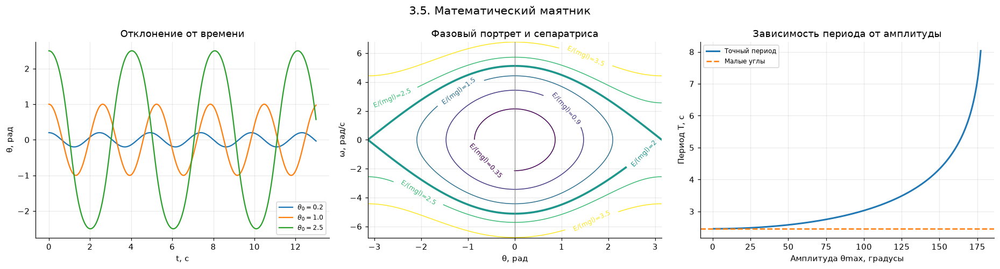

Период при малых углах: 2.4569 с


In [12]:
# 3.5 — численная модель маятника и точный период через эллиптический интеграл
ell35=1.5
w0_35=np.sqrt(g/ell35)
Tlin35=2*np.pi/w0_35

def rhs35(t,state):
    theta,omega=state
    return [omega,-(g/ell35)*np.sin(theta)]

def pendulum35(theta0,omega0,ts):
    sol=solve_ivp(rhs35,(float(ts[0]),float(ts[-1])),[theta0,omega0],
                  t_eval=ts,rtol=1e-9,atol=1e-11)
    if not sol.success: raise RuntimeError(sol.message)
    return sol.y[0],sol.y[1]

# Движение при нескольких начальных отклонениях
ts35=np.linspace(0,13,800)
fig,axs=plt.subplots(1,3,figsize=(17,4.6))
for alpha in [.2,1.0,2.5]:
    theta,omega=pendulum35(alpha,0,ts35)
    axs[0].plot(ts35,theta,label=fr'$\theta_0={alpha:.1f}$')
axs[0].set(xlabel='t, с',ylabel='θ, рад',title='Отклонение от времени')
axs[0].legend(fontsize=8)

# Фазовый портрет и области разных типов движения
angles=np.linspace(-np.pi,np.pi,350)
vels=np.linspace(-2.65*w0_35,2.65*w0_35,320)
TH,OM=np.meshgrid(angles,vels)
Ebar=.5*(ell35/g)*(OM**2)+(1-np.cos(TH))  # E/(m g l)
levels=[.35,.9,1.5,2.0,2.5,3.5]
cont=axs[1].contour(TH,OM,Ebar,levels=levels,linewidths=[1,1,1,2.4,1,1])
axs[1].clabel(cont,inline=True,fontsize=8,fmt='E/(mgl)=%.2g')
axs[1].set(xlabel='θ, рад',ylabel='ω, рад/с',title='Фазовый портрет и сепаратриса')
axs[1].axvline(0,color='gray',linewidth=.7)

# Зависимость периода от начальной амплитуды
alphas=np.linspace(.01,.985*np.pi,260)
periods=4*np.sqrt(ell35/g)*ellipk(np.sin(alphas/2)**2)
axs[2].plot(np.rad2deg(alphas),periods,lw=2,label='Точный период')
axs[2].axhline(Tlin35,color='tab:orange',ls='--',lw=1.7,label='Малые углы')
axs[2].set(xlabel='Амплитуда θmax, градусы',ylabel='Период T, с',title='Зависимость периода от амплитуды')
axs[2].legend(fontsize=8)
fig.suptitle('3.5. Математический маятник',fontsize=14)
fig.tight_layout()
save_figure(fig,'3_5_pendulum.png')
plt.show()
print(f'Период при малых углах: {Tlin35:.4f} с')

In [ ]:
# 3.5 — интерактивная анимация: маятники и синхронное движение в фазовом пространстве
# Режимы: малые колебания, большие колебания, вращение.
init35=[('Малые колебания',.35,0,'tab:blue'),
        ('Большие колебания',2.45,0,'tab:orange'),
        ('Вращение',.25,2.4*w0_35,'tab:green')]
tanimate35=np.linspace(0,10,200)
solutions35=[]
for name,angle0,vel0,color in init35:
    th,om=pendulum35(angle0,vel0,tanimate35)
    solutions35.append((name,th,om,color))

fig,axs=plt.subplots(1,2,figsize=(12.5,5.9))
axphys,axphase=axs
axphys.set(xlim=(-1.8*ell35,1.8*ell35),ylim=(-1.8*ell35,.6*ell35),
           xlabel='x, м',ylabel='y, м',title='Физическое движение маятников')
axphys.set_aspect('equal')
axphys.plot([0],[0],'ks',ms=7,label='Точка подвеса')
axphys.add_patch(Circle((0,0),ell35,fill=False,lw=.7,ls='--',ec='gray'))

phase_theta=np.linspace(-np.pi,np.pi,300)
phase_w=np.linspace(-3*w0_35,3*w0_35,250)
PHI,W=np.meshgrid(phase_theta,phase_w)
phaseE=.5*(ell35/g)*W**2+1-np.cos(PHI)
# axphase.contour(PHI,W,phaseE,levels=[.5,1.3,2,3.5],alpha=.55)
axphase.set(xlim=(-np.pi,np.pi),ylim=(-3*w0_35,3*w0_35),
            xlabel='θ (приведён к [−π,π]), рад',ylabel='ω, рад/с',title='Фазовый портрет (движущиеся точки)')

rods35=[];bobs35=[];dots35=[];traces35=[]
for name,theta,omega,color in solutions35:
    (rod,)=axphys.plot([],[],lw=2,color=color)
    (bob,)=axphys.plot([],[],'o',ms=10,color=color,label=name)
    (dot,)=axphase.plot([],[],'o',ms=8,color=color)
    (trail,)=axphase.plot([],[],lw=1.4,alpha=.45,color=color)
    rods35.append(rod); bobs35.append(bob)
    dots35.append(dot); traces35.append(trail)
axphys.legend(loc='lower center',fontsize=8)
info35=fig.text(.5,.01,'',ha='center')
def update35(i):
    for j,(name,thetas,omegas,color) in enumerate(solutions35):
        ang=thetas[i]
        bx=ell35*np.sin(ang)
        by=-ell35*np.cos(ang)
        rods35[j].set_data([0,bx],[0,by])
        bobs35[j].set_data([bx],[by])
        ph=((ang+np.pi)%(2*np.pi))-np.pi
        dots35[j].set_data([ph],[omegas[i]])
        past=((thetas[:i+1]+np.pi)%(2*np.pi))-np.pi
        past=np.where(np.abs(np.diff(past,prepend=past[0]))>np.pi,np.nan,past)
        traces35[j].set_data(past,omegas[:i+1])
    info35.set_text(f't = {tanimate35[i]:.2f} с    |    синий: малые колебания; оранжевый: большие; зелёный: вращение')
    return (*rods35,*bobs35,*dots35,*traces35,info35)
fig.tight_layout(rect=[0,.035,1,1])
anim35=show_animation(fig,update35,frames=len(tanimate35),interval=50,
                      filename='3_5_pendulum_animation.html')